<a href="https://colab.research.google.com/github/mugalan/vibration-analysis/blob/main/answers-to-selected-assignments/answer-to-2dof-flutter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brentq, linear_sum_assignment
from scipy.sparse.linalg import expm_multiply
from pathlib import Path

# ------------------------------------------------------
# Figure settings
# ------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "svg.fonttype": "path"
})

figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)


def save_figure(fig, name):
    """Save the same figure as SVG and PNG."""

    for extension in ["svg", "png"]:
        fig.savefig(
            figure_dir / f"{name}.{extension}",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.08
        )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------
# Structural parameters
# ------------------------------------------------------

M = 1.0
I = 0.02

K_y = 100.0
K_theta = 8.0

C_y = 0.2
C_theta = 0.01

# ------------------------------------------------------
# Aerodynamic parameters
# ------------------------------------------------------

rho_f = 1.225
S = 0.1
CL_alpha = 2 * np.pi
e = 0.05

# Undamped structural natural frequencies

omega_y = np.sqrt(K_y / M)
omega_theta = np.sqrt(K_theta / I)

print(f"omega_y     = {omega_y:.4f} rad/s")
print(f"omega_theta = {omega_theta:.4f} rad/s")

omega_y     = 10.0000 rad/s
omega_theta = 20.0000 rad/s


In [2]:
def a(U):
    """Aerodynamic stiffness coefficient."""
    return 0.5 * rho_f * U**2 * S * CL_alpha


def b(U):
    """Aerodynamic damping coefficient."""
    return 0.5 * rho_f * U * S * CL_alpha


def Gamma(U):
    """Mass-normalized damping matrix."""

    return np.array([
        [(C_y + b(U)) / M, 0.0],
        [e * b(U) / I, C_theta / I]
    ])


def Omega(U):
    """Mass-normalized stiffness matrix."""

    return np.array([
        [K_y / M, -a(U) / M],
        [0.0, (K_theta - e * a(U)) / I]
    ])


def system_matrix(U):
    """First-order state-space matrix."""

    return np.block([
        [np.zeros((2, 2)), np.eye(2)],
        [-Omega(U), -Gamma(U)]
    ])


def polynomial_coefficients(U):
    """Characteristic polynomial coefficients."""

    aa = a(U)
    bb = b(U)

    p4 = M * I

    p3 = M * C_theta + I * (C_y + bb)

    p2 = (
        M * (K_theta - e * aa)
        + I * K_y
        + (C_y + bb) * C_theta
    )

    p1 = (
        C_y * (K_theta - e * aa)
        + bb * K_theta
        + K_y * C_theta
    )

    p0 = K_y * (K_theta - e * aa)

    return np.array([p4, p3, p2, p1, p0])


def characteristic_roots(U):
    """Compute the characteristic roots."""

    return np.roots(polynomial_coefficients(U))


def growth_rate(U):
    """Maximum real part of the characteristic roots."""

    return np.max(characteristic_roots(U).real)


def routh_quantities(U):
    """Quantities defining Routh-Hurwitz stability."""

    p4, p3, p2, p1, p0 = polynomial_coefficients(U)

    D2 = p3 * p2 - p4 * p1

    D3 = (
        p3 * p2 * p1
        - p4 * p1**2
        - p3**2 * p0
    )

    return np.array([p3, D2, D3, p0])


def R(U):
    """Routh-Hurwitz flutter condition."""

    return routh_quantities(U)[2]


def is_stable(U):
    """Check the Routh-Hurwitz stability conditions."""

    return np.all(routh_quantities(U) > 0)


# ------------------------------------------------------
# Static divergence speed
# ------------------------------------------------------

if e > 0:

    U_d = np.sqrt(
        2 * K_theta / (e * rho_f * S * CL_alpha)
    )

else:

    U_d = np.inf


# ------------------------------------------------------
# Locate the first flutter boundary
# ------------------------------------------------------

def find_flutter_speed(U_max, n=5000):

    U_values = np.linspace(0, U_max, n)

    for Ul, Ur in zip(U_values[:-1], U_values[1:]):

        if R(Ul) > 0 and R(Ur) <= 0:

            Uf = brentq(
                R, Ul, Ur, xtol=1e-12
            )

            p4, p3, p2, p1, p0 = (
                polynomial_coefficients(Uf)
            )

            D2 = p3 * p2 - p4 * p1

            du = max(1e-6, 1e-5 * Uf)

            if (
                p3 > 0
                and p1 > 0
                and D2 > 0
                and p0 > 0
                and is_stable(max(0, Uf - du))
                and growth_rate(Uf + du) > 0
            ):
                return Uf

    raise RuntimeError(
        "No flutter boundary found in the search interval."
    )


U_search = min(U_d * (1 - 1e-8), 100.0)

U_f = find_flutter_speed(U_search)

p4, p3, p2, p1, p0 = polynomial_coefficients(U_f)

omega_f = np.sqrt(p1 / p3)

print(f"Flutter speed     = {U_f:.6f} m/s")
print(f"Divergence speed  = {U_d:.6f} m/s")
print(f"Flutter frequency = {omega_f:.6f} rad/s")

print("\nCharacteristic roots at flutter:")
print(characteristic_roots(U_f))

# Independently verify the roots using the
# first-order state-space representation.

np.testing.assert_allclose(
    np.sort_complex(characteristic_roots(U_f)),
    np.sort_complex(
        np.linalg.eigvals(system_matrix(U_f))
    ),
    atol=1e-8
)

Flutter speed     = 7.104025 m/s
Divergence speed  = 20.389990 m/s
Flutter frequency = 18.801345 rad/s

Characteristic roots at flutter:
[-3.10862447e-15+18.80134493j -3.10862447e-15-18.80134493j
 -1.71697467e+00 +9.82208166j -1.71697467e+00 -9.82208166j]


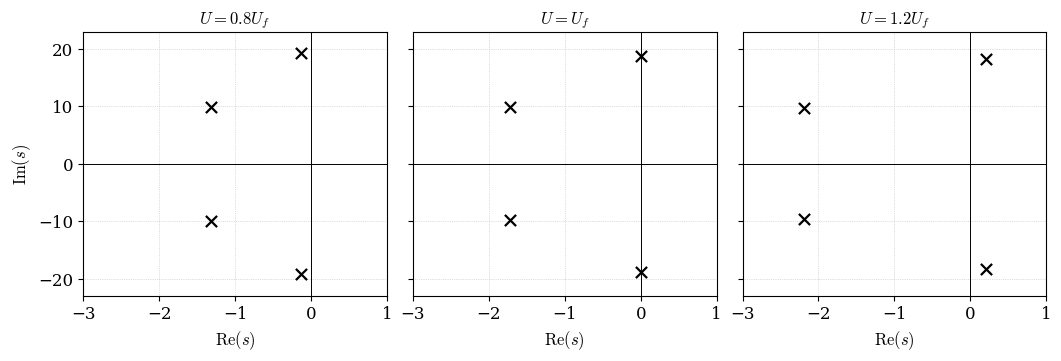

In [3]:
U_cases = [
    0.8 * U_f,
    U_f,
    1.2 * U_f
]

titles = [
    r"$U=0.8U_f$",
    r"$U=U_f$",
    r"$U=1.2U_f$"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(10.5, 3.5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, U, title in zip(axes, U_cases, titles):

    roots = characteristic_roots(U)

    ax.axhline(
        0, color="black", linewidth=0.7
    )

    ax.axvline(
        0, color="black", linewidth=0.7
    )

    ax.scatter(
        roots.real,
        roots.imag,
        color="black",
        marker="x",
        s=65,
        linewidths=1.6,
        zorder=3
    )

    ax.set_title(title)
    ax.set_xlabel(r"$\mathrm{Re}(s)$")

    ax.set_xlim(-3, 1)
    ax.set_ylim(-23, 23)

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.5,
        color="0.75"
    )

axes[0].set_ylabel(r"$\mathrm{Im}(s)$")

save_figure(fig, "flutter_root_crossing")

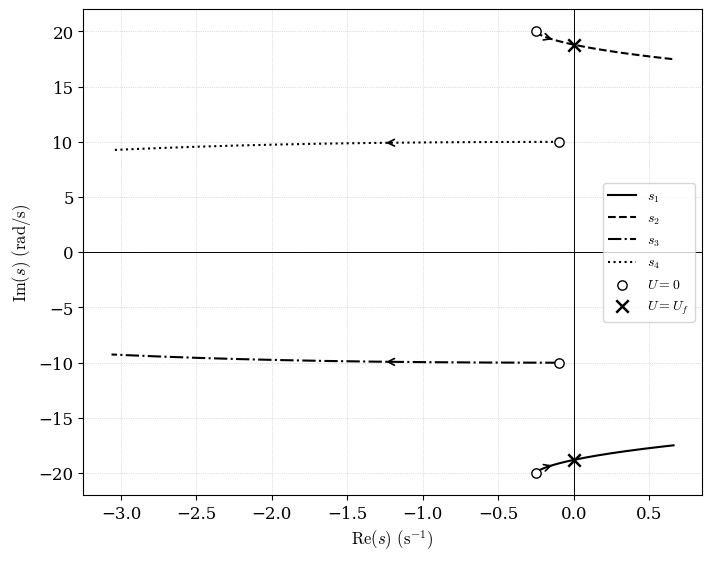

In [4]:
def track_characteristic_roots(U_values):
    """
    Track the individual characteristic roots
    as the airflow speed is varied.
    """

    roots = np.empty(
        (len(U_values), 4),
        dtype=complex
    )

    roots[0] = np.sort_complex(
        characteristic_roots(U_values[0])
    )

    for k in range(1, len(U_values)):

        previous = roots[k - 1]

        current = characteristic_roots(
            U_values[k]
        )

        # Cost of matching each old root
        # with each new root.

        cost = np.abs(
            previous[:, None] - current[None, :]
        )

        rows, columns = linear_sum_assignment(cost)

        roots[k, rows] = current[columns]

    return roots


U_values = np.linspace(0, 1.5 * U_f, 1500)

roots = track_characteristic_roots(U_values)

fig, ax = plt.subplots(
    figsize=(7, 5.5),
    constrained_layout=True
)

styles = ["-", "--", "-.", ":"]

for k in range(4):

    ax.plot(
        roots[:, k].real,
        roots[:, k].imag,
        color="black",
        linestyle=styles[k],
        label=rf"$s_{k+1}$"
    )

    # Indicate the direction of increasing U.

    n = len(U_values) // 2

    ax.annotate(
        "",
        xy=(
            roots[n + 20, k].real,
            roots[n + 20, k].imag
        ),
        xytext=(
            roots[n - 20, k].real,
            roots[n - 20, k].imag
        ),
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            linewidth=1.2
        )
    )


# Mark the roots at U = 0.

ax.scatter(
    roots[0].real,
    roots[0].imag,
    marker="o",
    facecolors="white",
    edgecolors="black",
    s=45,
    label=r"$U=0$",
    zorder=5
)

# Mark the critical flutter roots.

ax.scatter(
    [0, 0],
    [omega_f, -omega_f],
    color="black",
    marker="x",
    s=80,
    linewidths=1.8,
    label=r"$U=U_f$",
    zorder=6
)

ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)

ax.set_xlabel(r"$\mathrm{Re}(s)$ $(\mathrm{s}^{-1})$")
ax.set_ylabel(r"$\mathrm{Im}(s)$ $(\mathrm{rad/s})$")

ax.grid(
    True,
    linestyle=":",
    color="0.75",
    linewidth=0.5
)

ax.legend(loc="best")

save_figure(fig, "flutter_root_locus")

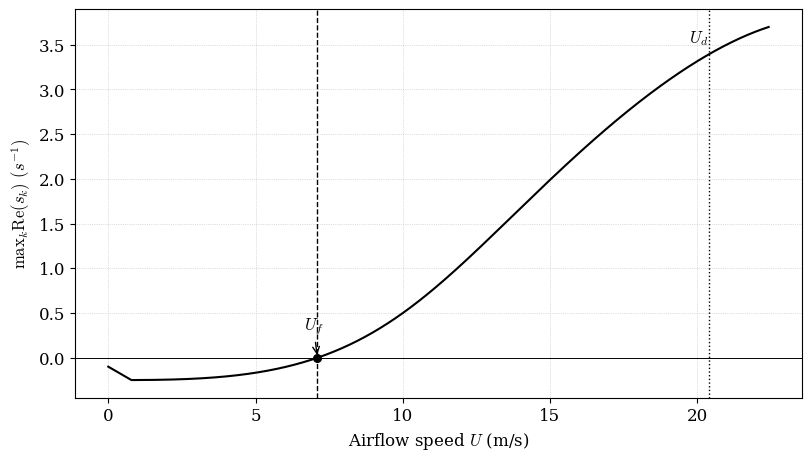

In [10]:
U_values = np.linspace(
    0,
    1.1 * U_d,
    2000
)

sigma_values = np.array([
    growth_rate(U) for U in U_values
])

fig, ax = plt.subplots(
    figsize=(8, 4.5),
    constrained_layout=True
)

ax.plot(
    U_values,
    sigma_values,
    color="black"
)

ax.axhline(
    0,
    color="black",
    linewidth=0.7
)

ax.axvline(
    U_f,
    color="black",
    linestyle="--",
    linewidth=1.0
)

ax.axvline(
    U_d,
    color="black",
    linestyle=":",
    linewidth=1.0
)

ax.scatter(
    [U_f], [0],
    color="black",
    marker="o",
    s=30,
    zorder=4
)

ax.annotate(
    r"$U_f$",
    xy=(U_f, 0),
    xytext=(-10, 20),
    textcoords="offset points",
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    )
)

ax.text(
    U_d,
    0.95,
    r"$U_d$",
    transform=ax.get_xaxis_transform(),
    ha="right",
    va="top"
)

ax.set_xlabel(r"Airflow speed $U$ (m/s)")

ax.set_ylabel(
    r"$\mathrm{max}_k\mathrm{Re}(s_k)$"
    r" $({s}^{-1})$"
)

ax.grid(
    True,
    linestyle=":",
    color="0.75",
    linewidth=0.5
)

save_figure(fig, "flutter_growth_rate")

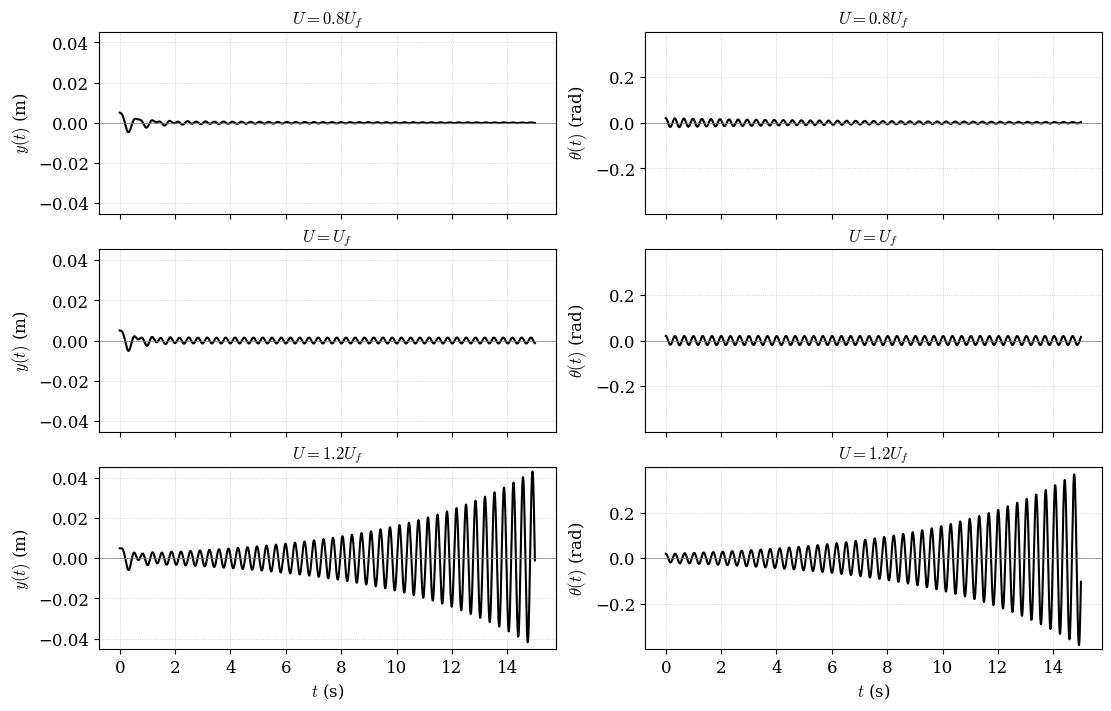

In [8]:
# Initial conditions:
#
# X = [y, theta, dy/dt, dtheta/dt]

X0 = np.array([
    0.005,
    0.02,
    0.0,
    0.0
])


def simulate(U, t, X0):

    """
    Compute the exact LTI response, up to
    numerical matrix-exponential evaluation.

    The time array must be uniformly spaced.
    """

    A = system_matrix(U)

    X = expm_multiply(
        A,
        X0,
        start=t[0],
        stop=t[-1],
        num=len(t),
        endpoint=True
    )

    return X


t = np.linspace(0, 15, 3001)

responses = [
    simulate(U, t, X0)
    for U in U_cases
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(11, 7),
    sharex=True,
    constrained_layout=True
)

for j, (U, X, title) in enumerate(
    zip(U_cases, responses, titles)
):

    y = X[:, 0]
    theta = X[:, 1]

    axes[j, 0].plot(
        t,
        y,
        color="black"
    )

    axes[j, 1].plot(
        t,
        theta,
        color="black"
    )

    axes[j, 0].set_ylabel(
        r"$y(t)$ (m)"
    )

    axes[j, 1].set_ylabel(
        r"$\theta(t)$ (rad)"
    )

    axes[j, 0].set_title(title)
    axes[j, 1].set_title(title)

    for ax in axes[j]:

        ax.axhline(
            0,
            color="0.5",
            linewidth=0.5
        )

        ax.grid(
            True,
            linestyle=":",
            linewidth=0.5,
            color="0.75"
        )

# Use common limits for each physical quantity
# to make the responses directly comparable.

y_max = max(
    np.max(np.abs(X[:, 0]))
    for X in responses
)

theta_max = max(
    np.max(np.abs(X[:, 1]))
    for X in responses
)

for j in range(3):

    axes[j, 0].set_ylim(
        -1.05 * y_max,
        1.05 * y_max
    )

    axes[j, 1].set_ylim(
        -1.05 * theta_max,
        1.05 * theta_max
    )

axes[-1, 0].set_xlabel(r"$t$ (s)")
axes[-1, 1].set_xlabel(r"$t$ (s)")

save_figure(fig, "flutter_time_response")

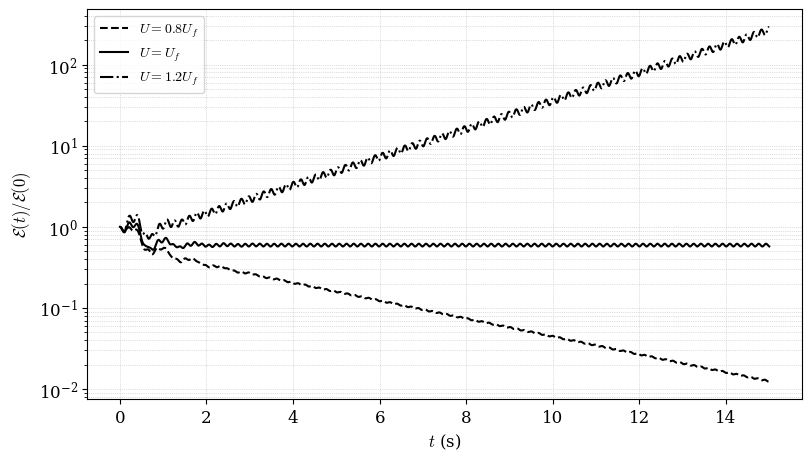

In [9]:
def mechanical_energy(X):

    y = X[:, 0]
    theta = X[:, 1]

    y_dot = X[:, 2]
    theta_dot = X[:, 3]

    E = (
        0.5 * M * y_dot**2
        + 0.5 * I * theta_dot**2
        + 0.5 * K_y * y**2
        + 0.5 * K_theta * theta**2
    )

    return E


def aerodynamic_power(U, X):

    theta = X[:, 1]
    y_dot = X[:, 2]
    theta_dot = X[:, 3]

    F_a = a(U) * theta - b(U) * y_dot
    T_a = e * F_a

    return (
        F_a * y_dot
        + T_a * theta_dot
    )


def dissipated_power(X):

    y_dot = X[:, 2]
    theta_dot = X[:, 3]

    return (
        C_y * y_dot**2
        + C_theta * theta_dot**2
    )


def energy_rate(U, X):

    return (
        aerodynamic_power(U, X)
        - dissipated_power(X)
    )


# ------------------------------------------------------
# Mechanical energy for the three cases
# ------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 4.5),
    constrained_layout=True
)

styles = ["--", "-", "-."]

E0 = mechanical_energy(X0[None, :])[0]

for U, X, style, title in zip(
    U_cases,
    responses,
    styles,
    titles
):

    E = mechanical_energy(X)

    ax.semilogy(
        t,
        E / E0,
        color="black",
        linestyle=style,
        label=title
    )

ax.set_xlabel(r"$t$ (s)")

ax.set_ylabel(
    r"$\mathcal{E}(t)/\mathcal{E}(0)$"
)

ax.grid(
    True,
    which="both",
    linestyle=":",
    color="0.75",
    linewidth=0.5
)

ax.legend()

save_figure(fig, "flutter_energy_response")

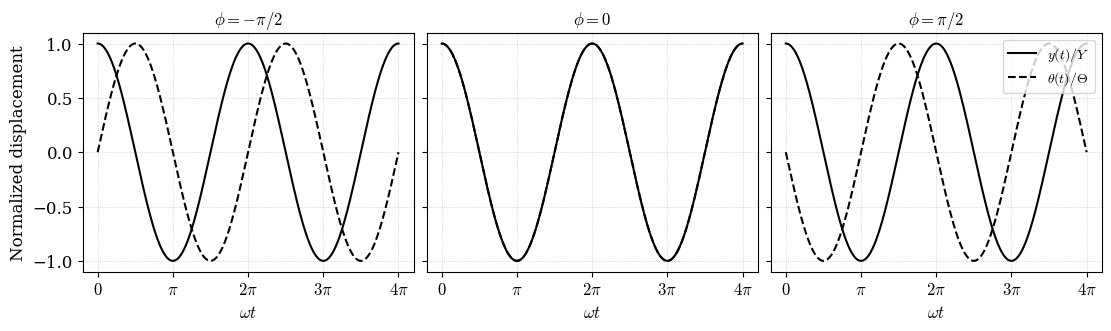

In [11]:
tau = np.linspace(0, 4 * np.pi, 1000)

phase_values = [
    -np.pi / 2,
    0,
    np.pi / 2
]

phase_labels = [
    r"$\phi=-\pi/2$",
    r"$\phi=0$",
    r"$\phi=\pi/2$"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(11, 3.2),
    sharey=True,
    constrained_layout=True
)

for ax, phi, label in zip(
    axes, phase_values, phase_labels
):

    y = np.cos(tau)

    theta = np.cos(tau + phi)

    ax.plot(
        tau,
        y,
        color="black",
        linestyle="-",
        label=r"$y(t)/Y$"
    )

    ax.plot(
        tau,
        theta,
        color="black",
        linestyle="--",
        label=r"$\theta(t)/\Theta$"
    )

    ax.set_title(label)

    ax.set_xlabel(r"$\omega t$")

    ax.set_xticks([
        0,
        np.pi,
        2 * np.pi,
        3 * np.pi,
        4 * np.pi
    ])

    ax.set_xticklabels([
        r"$0$",
        r"$\pi$",
        r"$2\pi$",
        r"$3\pi$",
        r"$4\pi$"
    ])

    ax.grid(
        True,
        linestyle=":",
        color="0.75",
        linewidth=0.5
    )

axes[0].set_ylabel("Normalized displacement")
axes[-1].legend(loc="upper right")

save_figure(fig, "flutter_phase_difference")

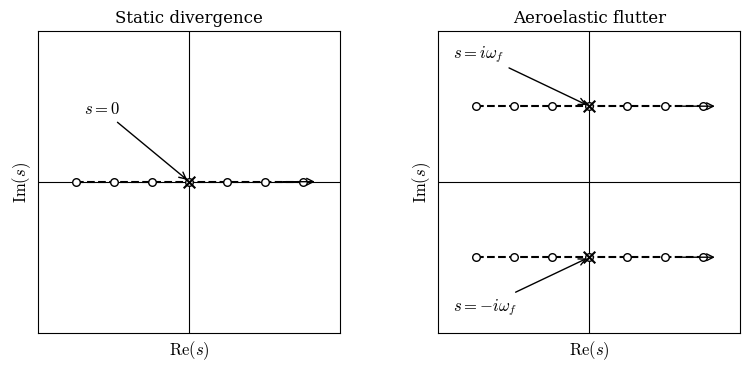

In [12]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(8, 3.6),
    constrained_layout=True
)

for ax in axes:

    ax.axhline(
        0, color="black", linewidth=0.8
    )

    ax.axvline(
        0, color="black", linewidth=0.8
    )

    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)

    ax.set_xlabel(r"$\mathrm{Re}(s)$")
    ax.set_ylabel(r"$\mathrm{Im}(s)$")

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_aspect("equal")


# Static divergence

ax = axes[0]

ax.set_title("Static divergence")

real_positions = np.linspace(-1.5, 1.5, 7)

ax.plot(
    real_positions,
    np.zeros_like(real_positions),
    color="black",
    linestyle="--"
)

ax.scatter(
    real_positions,
    np.zeros_like(real_positions),
    marker="o",
    facecolors="white",
    edgecolors="black",
    s=30,
    zorder=3
)

ax.scatter(
    [0], [0],
    color="black",
    marker="x",
    s=70,
    zorder=4
)

ax.annotate(
    "",
    xy=(1.7, 0),
    xytext=(1.2, 0),
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    )
)

ax.annotate(
    r"$s=0$",
    xy=(0, 0),
    xytext=(-1.4, 0.9),
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    )
)


# Aeroelastic flutter

ax = axes[1]

ax.set_title("Aeroelastic flutter")

for sign in [-1, 1]:

    imaginary_positions = (
        sign * np.ones_like(real_positions)
    )

    ax.plot(
        real_positions,
        imaginary_positions,
        color="black",
        linestyle="--"
    )

    ax.scatter(
        real_positions,
        imaginary_positions,
        marker="o",
        facecolors="white",
        edgecolors="black",
        s=30,
        zorder=3
    )

    ax.scatter(
        [0], [sign],
        color="black",
        marker="x",
        s=70,
        zorder=4
    )

    ax.annotate(
        "",
        xy=(1.7, sign),
        xytext=(1.2, sign),
        arrowprops=dict(
            arrowstyle="->",
            color="black"
        )
    )

ax.annotate(
    r"$s=i\omega_f$",
    xy=(0, 1),
    xytext=(-1.8, 1.65),
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    )
)

ax.annotate(
    r"$s=-i\omega_f$",
    xy=(0, -1),
    xytext=(-1.8, -1.7),
    arrowprops=dict(
        arrowstyle="->",
        color="black"
    )
)

save_figure(fig, "flutter_vs_divergence")

In [13]:
import shutil

archive = shutil.make_archive(
    "exercise_2_10_flutter_figures",
    "zip",
    root_dir="figures"
)

print(f"Created: {archive}")

# Download when running in Google Colab.

try:

    from google.colab import files
    files.download(archive)

except ImportError:

    print("The ZIP archive is available locally.")

Created: /content/exercise_2_10_flutter_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>